In [1]:
import kagglehub
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

path = kagglehub.dataset_download("snap/amazon-fine-food-reviews")
print("Veri seti yolu:", path)

Veri seti yolu: C:\Users\Umut\.cache\kagglehub\datasets\snap\amazon-fine-food-reviews\versions\2


In [2]:
df = pd.read_csv(os.path.join(path, "Reviews.csv"))
df = df[['Score', 'Text']].dropna()

# Tekrar eden kopya yorumları temizle (Data Leakage önlemi)
df = df.drop_duplicates(subset=['Text'], keep='first')

# Nötr (3 puan) yorumları çıkar
df = df[df['Score'] != 3]

# İkili etiketleme: 4-5 -> Pozitif (1), 1-2 -> Negatif (0)
df['sentiment'] = df['Score'].apply(lambda x: 1 if x > 3 else 0)

print(df['sentiment'].value_counts())
df.head()

sentiment
1    306758
0     57067
Name: count, dtype: int64


,Score,Text,sentiment
0,5,I have bought several of the Vitality canned d...,1
1,1,Product arrived labeled as Jumbo Salted Peanut...,0
2,4,This is a confection that has been around a fe...,1
3,2,If you are looking for the secret ingredient i...,0
4,5,Great taffy at a great price. There was a wid...,1


In [3]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

# Olumsuzluk bildiren kelimeleri stopwords listesinden çıkar
negations = {
    'no', 'not', 'nor', 'neither', 'never', 'none',
    "don't", "didn't", "wasn't", "weren't", "haven't",
    "hasn't", "hadn't", "won't", "wouldn't", "shouldn't",
    "couldn't", "can't", "cannot"
}
stop_words = stop_words - negations

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    words = text.split()
    words = [lemmatizer.lemmatize(w) for w in words if w not in stop_words and len(w) > 1]
    return ' '.join(words)

df['clean_text'] = df['Text'].apply(clean_text)
df[['Text', 'clean_text', 'sentiment']].head()

,Text,clean_text,sentiment
0,I have bought several of the Vitality canned d...,bought several vitality canned dog food produc...,1
1,Product arrived labeled as Jumbo Salted Peanut...,product arrived labeled jumbo salted peanut pe...,0
2,This is a confection that has been around a fe...,confection around century light pillowy citrus...,1
3,If you are looking for the secret ingredient i...,looking secret ingredient robitussin believe f...,0
4,Great taffy at a great price. There was a wid...,great taffy great price wide assortment yummy ...,1


In [4]:
X = df['clean_text']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=20000,
    min_df=5,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Eğitim matrisi boyutu:", X_train_tfidf.shape)
print("Test matrisi boyutu:", X_test_tfidf.shape)

Eğitim matrisi boyutu: (291060, 20000)
Test matrisi boyutu: (72765, 20000)


In [5]:
# 1. Logistic Regression
lr_model = LogisticRegression(C=1.5, solver='saga', class_weight='balanced', max_iter=1000, random_state=42)
lr_model.fit(X_train_tfidf, y_train)
y_pred_lr = lr_model.predict(X_test_tfidf)

print("--- Logistic Regression Sonuçları ---")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

# 2. Multinomial Naive Bayes
sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train, sample_weight=sample_weights)
y_pred_nb = nb_model.predict(X_test_tfidf)

print("--- Multinomial Naive Bayes Sonuçları ---")
print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print(classification_report(y_test, y_pred_nb))

# 3. Linear Support Vector Machine (LinearSVC)
svm_model = LinearSVC(C=0.5, class_weight='balanced', random_state=42)
svm_model.fit(X_train_tfidf, y_train)
y_pred_svm = svm_model.predict(X_test_tfidf)

print("--- LinearSVC (SVM) Sonuçları ---")
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print(classification_report(y_test, y_pred_svm))

--- Logistic Regression Sonuçları ---
Accuracy: 0.9194667766096337
              precision    recall  f1-score   support

           0       0.69      0.90      0.78     11413
           1       0.98      0.92      0.95     61352

    accuracy                           0.92     72765
   macro avg       0.83      0.91      0.86     72765
weighted avg       0.93      0.92      0.92     72765

--- Multinomial Naive Bayes Sonuçları ---
Accuracy: 0.889892118463547
              precision    recall  f1-score   support

           0       0.60      0.89      0.72     11413
           1       0.98      0.89      0.93     61352

    accuracy                           0.89     72765
   macro avg       0.79      0.89      0.82     72765
weighted avg       0.92      0.89      0.90     72765

--- LinearSVC (SVM) Sonuçları ---
Accuracy: 0.9191919191919192
              precision    recall  f1-score   support

           0       0.69      0.89      0.78     11413
           1       0.98      0.92    

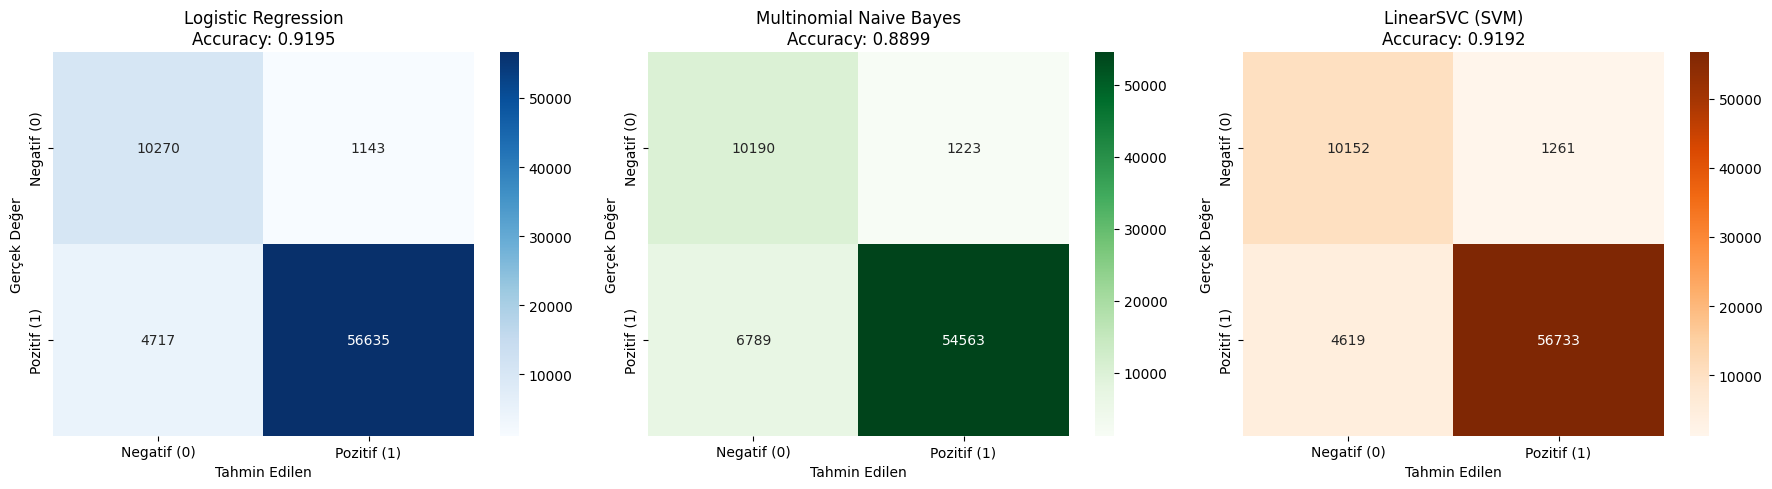

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models_preds = [
    ("Logistic Regression", y_pred_lr, "Blues"),
    ("Multinomial Naive Bayes", y_pred_nb, "Greens"),
    ("LinearSVC (SVM)", y_pred_svm, "Oranges")
]

for ax, (title, preds, cmap) in zip(axes, models_preds):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=ax,
                xticklabels=['Negatif (0)', 'Pozitif (1)'],
                yticklabels=['Negatif (0)', 'Pozitif (1)'])
    ax.set_title(f"{title}\nAccuracy: {accuracy_score(y_test, preds):.4f}")
    ax.set_ylabel('Gerçek Değer')
    ax.set_xlabel('Tahmin Edilen')

plt.tight_layout()
plt.show()

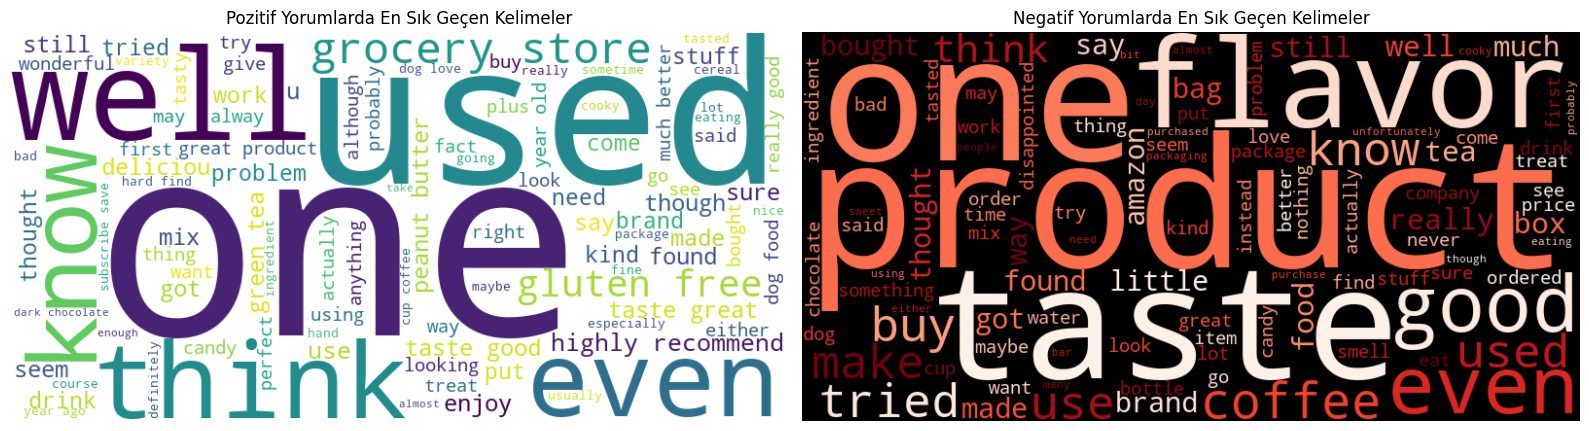

In [7]:
pos_text = ' '.join(df[df['sentiment'] == 1]['clean_text'])
neg_text = ' '.join(df[df['sentiment'] == 0]['clean_text'])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

wc_pos = WordCloud(width=800, height=400, background_color='white', max_words=100).generate(pos_text)
axes[0].imshow(wc_pos, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title('Pozitif Yorumlarda En Sık Geçen Kelimeler')

wc_neg = WordCloud(width=800, height=400, background_color='black', colormap='Reds', max_words=100).generate(neg_text)
axes[1].imshow(wc_neg, interpolation='bilinear')
axes[1].axis('off')
axes[1].set_title('Negatif Yorumlarda En Sık Geçen Kelimeler')

plt.tight_layout()
plt.show()

In [8]:
def test_yorum_analizi(kullanici_yorumu):
    if not kullanici_yorumu.strip():
        print("Geçersiz yorum!")
        return

    temiz_metin = clean_text(kullanici_yorumu)
    vektor = tfidf.transform([temiz_metin])

    # 3 modelin tahmini
    pred_lr = lr_model.predict(vektor)[0]
    prob_lr = lr_model.predict_proba(vektor)[0]  # Güven oranı (%)

    pred_nb = nb_model.predict(vektor)[0]
    pred_svm = svm_model.predict(vektor)[0]

    print(f"Orijinal Metin     : {kullanici_yorumu}")
    print(f"Temizlenmiş Metin : {temiz_metin}")
    print(f"Logistic Regression: {'POZİTİF (1)' if pred_lr == 1 else 'NEGATİF (0)'} (Güven: %{max(prob_lr)*100:.1f})")
    print(f"Multinomial NB     : {'POZİTİF (1)' if pred_nb == 1 else 'NEGATİF (0)'}")
    print(f"LinearSVC (SVM)    : {'POZİTİF (1)' if pred_svm == 1 else 'NEGATİF (0)'}")
    print("-" * 55)

In [9]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Çıktıların temizlenip yeniden yazılacağı dinamik alan
out = widgets.Output()

def canli_analiz_tetikleyici(change):
    with out:
        clear_output(wait=True)
        yeni_yorum = change['new']
        if yeni_yorum.strip():
            test_yorum_analizi(yeni_yorum)
        else:
            print("Lütfen analiz etmek için bir şeyler yazın...")

# Canlı metin giriş kutusu (Her tuş vuruşunda tetiklenmesi için continuous_update=True yapıldı)
metin_kutusu = widgets.Text(
    value='fucking amazing',
    placeholder='İngilizce yorumunuzu buraya yazın...',
    description='Yorum:',
    disabled=False,
    continuous_update=True,
    layout=widgets.Layout(width='80%')
)

# Değişiklik olduğunda fonksiyonu tetikle
metin_kutusu.observe(canli_analiz_tetikleyici, names='value')

# Widget arayüzünü ekrana bas
display(widgets.HTML("<h3>Canlı Zamanlı Duygu Analizi</h3>"))
display(metin_kutusu)
display(out)

# Başlangıç durumu için ilk analizi yap
with out:
    test_yorum_analizi(metin_kutusu.value)

HTML(value='<h3>Canlı Zamanlı Duygu Analizi</h3>')

Text(value='fucking amazing', description='Yorum:', layout=Layout(width='80%'), placeholder='İngilizce yorumun…

Output()